# 재검정 1 — H1 (몰림)

**H1: 같은 노선 안에서 의존 정류장 승차가 그 노선의 다른 정류장보다 많았나?**

- 귀무가설: 같은 노선 안에서 의존 정류장과 다른 정류장의 (그 노선) 승차는 차이가 없다
- 대립가설: 의존 정류장이 더 많다

**의존 정류장** = 멀리 가는 노선(간선·지선·광역) ≤1 + 월 승차 ≥ 75퍼센타일 + 지하철역 300m 밖.

핵심 주의: 의존 정류장은 **정의에 '승차 상위 25%'가 들어 있다.**
그래서 아무 정류장과 비교하면 당연히 크다 →
**메인 비교는 같은 노선 안에서 "승차 ≥ 75퍼센타일 + 역 300m 밖"인 정류장끼리**,
의존(멀리 ≤1) vs 비의존(멀리 ≥2) 로 한다.

In [1]:
# 프로젝트 ROOT 찾아서 공통 경로·함수 불러오기 (경로 문자열은 src/paths.py에만)
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "src"))
from paths import RAW, EXT, PROC, REPORTS

print("ROOT:", ROOT)

ROOT: C:\study\aix\aix_2


In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import biv_stats as bs
from bus_util import D_MAIN, FAR, P75

mpl.rcParams["font.family"] = "Malgun Gothic"
mpl.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font="Malgun Gothic", rc={"axes.unicode_minus": False})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 230)

TARGET = "01278"
TARGET_ROUTE = "7016"
RB = "노선승차"          # 그 노선에서 그 정류장의 월 승차

stop = pd.read_csv(PROC / "stop_metrics_subway.csv", encoding="utf-8-sig",
                   dtype={"버스정류장ARS번호": str, "1위노선": str})
sr = pd.read_csv(PROC / "stop_route.csv", encoding="utf-8-sig",
                 dtype={"ARS": str, "노선번호": str})
print(stop.shape, sr.shape)

# 정류장 단위 속성 + 의존 정류장 플래그
attr = (stop.rename(columns={"버스정류장ARS번호": "ARS", "월승차": "정류장월승차"})
        [["ARS", "정류장명", "자치구", "정류장월승차", "멀리가는노선수", "가까운역거리m"]].copy())
attr["승차상위25"] = attr["정류장월승차"] >= P75
attr["역300m밖"] = attr["가까운역거리m"] > D_MAIN        # 거리 결측은 False
attr["의존"] = attr["승차상위25"] & attr["역300m밖"] & (attr["멀리가는노선수"] <= 1)
attr["비교군"] = attr["승차상위25"] & attr["역300m밖"] & (attr["멀리가는노선수"] >= 2)

print("의존 정류장:", int(attr["의존"].sum()), "/ 같은 조건 비의존:", int(attr["비교군"].sum()))

(10615, 24) (33992, 7)
의존 정류장: 155 / 같은 조건 비의존: 1334


## 1. 대상 노선 — 의존 정류장에 서는 멀리 가는 노선

In [3]:
far = (sr[sr["노선종류"].isin(FAR)]
       .rename(columns={"월승차": RB})
       .drop(columns=["자치구", "역명", "월하차"])      # attr 쪽 컬럼을 쓴다
       .merge(attr, on="ARS", how="inner"))

dep_ars = set(attr.loc[attr["의존"], "ARS"])
target_routes = set(far.loc[far["ARS"].isin(dep_ars), "노선번호"])
far = far[far["노선번호"].isin(target_routes)].copy()

routes = (far[far["ARS"].isin(dep_ars)]
          .groupby(["노선번호", "노선종류"], as_index=False)
          .agg(의존정류장수=("ARS", "nunique"))
          .merge(far.groupby("노선번호", as_index=False).agg(노선정류장수=("ARS", "nunique")),
                 on="노선번호")
          .sort_values("의존정류장수", ascending=False).reset_index(drop=True))
routes.index += 1

print(f"의존 정류장에 서는 멀리 가는 노선: {len(routes)}개 (멀리 가는 노선 전체 중)")
print("노선 종류별:", routes["노선종류"].value_counts().to_dict())
print("\n의존 정류장 수 상위 15개 노선:")
print(routes.head(15).to_string())
print("\n노선별 의존 정류장 수 분포:")
print(routes["의존정류장수"].value_counts().sort_index().to_string())

의존 정류장에 서는 멀리 가는 노선: 38개 (멀리 가는 노선 전체 중)
노선 종류별: {'지선': 24, '간선': 13, '광역': 1}

의존 정류장 수 상위 15개 노선:
    노선번호 노선종류  의존정류장수  노선정류장수
1    641   간선       3      98
2   5513   지선       3      44
3   5515   지선       3      31
4   1130   지선       2      27
5   1119   지선       2      61
6   1126   지선       2      54
7   4318   지선       2     107
8   6624   지선       2      70
9   4433   지선       2      36
10   147   간선       2     104
11   420   간선       2      85
12   271   간선       2     122
13   341   간선       2      93
14  3012   지선       2      96
15  1162   지선       1      33

노선별 의존 정류장 수 분포:
의존정류장수
1    24
2    11
3     3


## 2. 노선 안에서 정류장별 그 노선 승차 → 노선 내 백분위 순위 (0~1)

In [4]:
far["노선내백분위"] = far.groupby("노선번호")[RB].rank(pct=True)
print("노선×정류장 쌍:", len(far))
print(far[["ARS", "정류장명", "노선번호", RB, "노선내백분위", "의존", "비교군"]].head())
print("\n노선 내 백분위 요약:")
print(far["노선내백분위"].describe().round(3).to_string())

노선×정류장 쌍: 2666
      ARS           정류장명 노선번호   노선승차    노선내백분위     의존   비교군
13  01002    창경궁.서울대학교병원  171   6095  0.662651  False  True
15  01002    창경궁.서울대학교병원  272  11426  0.755319  False  True
29  01003      명륜3가.성대입구  171   7741  0.746988  False  True
31  01003      명륜3가.성대입구  272  15459  0.914894  False  True
49  01005  혜화동로터리.여운형활동터  171   3621  0.469880  False  True

노선 내 백분위 요약:
count    2666.000
mean        0.507
std         0.289
min         0.008
25%         0.258
50%         0.506
75%         0.757
max         1.000


## 3. 메인 비교 — 같은 조건(승차 상위 25% + 역 300m 밖)끼리 의존 vs 비의존

In [5]:
pool = far[far["의존"] | far["비교군"]].copy()
pool["구분"] = np.where(pool["의존"], "의존", "비의존")
print("메인 비교 대상 (노선×정류장 쌍):", len(pool))
print(pool["구분"].value_counts().to_string())
print("비교에 들어간 노선 수:", pool["노선번호"].nunique())

r_main = bs.group2(pool.loc[pool["구분"] == "의존", "노선내백분위"],
                   pool.loc[pool["구분"] == "비의존", "노선내백분위"],
                   "의존", "비의존", vname="노선내백분위")
r_raw = bs.group2(pool.loc[pool["구분"] == "의존", RB],
                  pool.loc[pool["구분"] == "비의존", RB],
                  "의존", "비의존", vname=RB)
pd.DataFrame([r_main, r_raw])[["변수", "방법", "n_의존", "n_비의존",
                               "중앙값_의존", "중앙값_비의존",
                               "평균_의존", "평균_비의존", "p표시", "별표",
                               "정규성_의존", "정규성_비의존"]]

메인 비교 대상 (노선×정류장 쌍): 879
구분
비의존    824
의존      55
비교에 들어간 노선 수: 38


,변수,방법,n_의존,n_비의존,중앙값_의존,중앙값_비의존,평균_의존,평균_비의존,p표시,별표,정규성_의존,정규성_비의존
0,노선내백분위,순위합 검정(W),55,824,0.9167,0.5895,0.8680,0.5722,p<0.05,**,p<0.05,p<0.05
1,노선승차,순위합 검정(W),55,824,11594.0000,5034.0000,12816.5636,5936.7755,p<0.05,**,p<0.05,p<0.05


## 4. 보조 — 노선별 (의존 중앙값 ÷ 비의존 중앙값)이 1보다 큰가

In [6]:
rows = []
for rt, g in pool.groupby("노선번호"):
    d = g.loc[g["구분"] == "의존", "노선내백분위"]
    n = g.loc[g["구분"] == "비의존", "노선내백분위"]
    if len(d) == 0 or len(n) == 0:
        continue
    rows.append({"노선번호": rt, "의존중앙값": d.median(), "비의존중앙값": n.median(),
                 "비율": d.median() / n.median(), "n_의존": len(d), "n_비의존": len(n)})
ratio = pd.DataFrame(rows)

n_all = len(target_routes)
print(f"의존 정류장이 있는 노선 {n_all}개 중 "
      f"같은 조건 비의존 정류장도 있어 비교 가능: {len(ratio)}개 "
      f"(비교 대상 없어 제외: {n_all - len(ratio)}개)")
print(f"비율 > 1 인 노선: {int((ratio['비율'] > 1).sum())} / {len(ratio)}")
print(f"비율 중앙값: {ratio['비율'].median():.3f}")

nrm, txt, _ = bs.normal(ratio["비율"])
print(f"\n비율의 정규성(Shapiro): {txt} → {'정규' if nrm else '정규 아님'}")
stat, p_w = stats.wilcoxon(ratio["비율"] - 1, alternative="two-sided")
print(f"Wilcoxon 부호순위 (비율 vs 1): {bs.ptxt(p_w)} {bs.star(p_w)}")
ratio.sort_values("비율", ascending=False).head(10).round(3)

의존 정류장이 있는 노선 38개 중 같은 조건 비의존 정류장도 있어 비교 가능: 37개 (비교 대상 없어 제외: 1개)
비율 > 1 인 노선: 34 / 37
비율 중앙값: 1.405

비율의 정규성(Shapiro): p>0.05 → 정규
Wilcoxon 부호순위 (비율 vs 1): p<0.05 **


,노선번호,의존중앙값,비의존중앙값,비율,n_의존,n_비의존
8,171,0.952,0.470,2.026,1,43
32,6624,0.964,0.479,2.015,2,22
6,130,0.977,0.494,1.977,1,38
7,147,0.918,0.481,1.910,2,37
28,5515,0.935,0.516,1.812,3,12
19,421,0.957,0.548,1.746,1,34
12,271,0.865,0.504,1.715,2,38
36,9401,1.000,0.583,1.714,1,2
15,3012,0.979,0.583,1.679,2,20
31,641,0.908,0.546,1.664,3,38


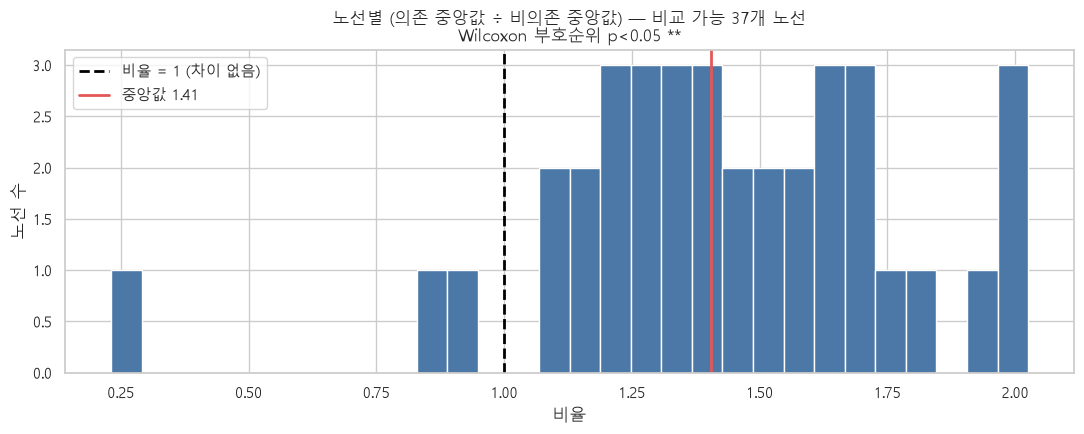

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(ratio["비율"], bins=30, color="#4C78A8")
ax.axvline(1, color="black", lw=2, ls="--", label="비율 = 1 (차이 없음)")
ax.axvline(ratio["비율"].median(), color="#E45756", lw=2,
           label=f"중앙값 {ratio['비율'].median():.2f}")
ax.set_title(f"노선별 (의존 중앙값 ÷ 비의존 중앙값) — 비교 가능 {len(ratio)}개 노선\n"
             f"Wilcoxon 부호순위 {bs.ptxt(p_w)} {bs.star(p_w)}")
ax.set_xlabel("비율"); ax.set_ylabel("노선 수"); ax.legend()
plt.tight_layout(); plt.show()

## 5. 참고 비교 — 같은 노선 전체 정류장 대비 (조건 안 맞춤)

**이 비교는 "정의상 당연"하다.** 의존 정류장 정의에 승차 상위 25%가 들어 있어
조건을 안 맞추면 반드시 크게 나온다. 참고로만 둔다.

In [8]:
ref = far.copy()
ref["구분"] = np.where(ref["의존"], "의존", "그외")
r_ref = bs.group2(ref.loc[ref["구분"] == "의존", "노선내백분위"],
                  ref.loc[ref["구분"] == "그외", "노선내백분위"],
                  "의존", "그외", vname="노선내백분위")
print("※ 정의상 당연 — 참고용")
pd.Series(r_ref).to_frame("값")

※ 정의상 당연 — 참고용


,값
변수,노선내백분위
방법,순위합 검정(W)
n_의존,55
n_그외,2611
중앙값_의존,0.9167
중앙값_그외,0.5
평균_의존,0.868
평균_그외,0.4995
p표시,p<0.05
별표,**


## 6. 박스플롯 + 상명대정문의 7016 노선 내 순위

상명대정문 @ 7016: 노선 승차 44,046, 노선 내 백분위 1.000 (105개 정류장 중 1위), 의존 True


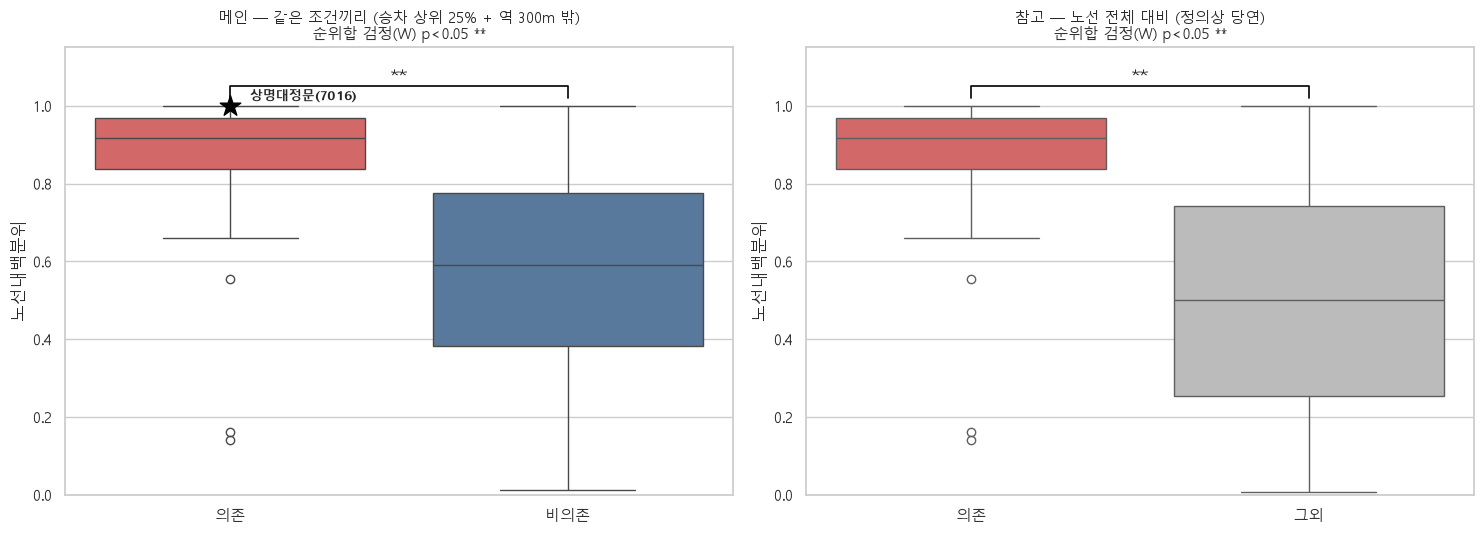

In [9]:
smd = far[(far["ARS"] == TARGET) & (far["노선번호"] == TARGET_ROUTE)]
if len(smd):
    s = smd.iloc[0]
    n7016 = far[far["노선번호"] == TARGET_ROUTE]
    rank_in = int((n7016[RB] > s[RB]).sum()) + 1
    print(f"상명대정문 @ {TARGET_ROUTE}: 노선 승차 {s[RB]:,.0f}, "
          f"노선 내 백분위 {s['노선내백분위']:.3f} "
          f"({len(n7016)}개 정류장 중 {rank_in}위), 의존 {bool(s['의존'])}")
else:
    print("상명대정문이 대상에 없다")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=pool, x="구분", y="노선내백분위", order=["의존", "비의존"], hue="구분",
            palette={"의존": "#E45756", "비의존": "#4C78A8"}, legend=False, ax=axes[0])
axes[0].plot([0, 0, 1, 1], [1.02, 1.05, 1.05, 1.02], lw=1.2, color="black")
axes[0].text(0.5, 1.06, r_main["별표"] or "n.s.", ha="center", fontsize=13)
axes[0].set_ylim(0, 1.15)
axes[0].set_title(f"메인 — 같은 조건끼리 (승차 상위 25% + 역 {D_MAIN}m 밖)\n"
                  f"{r_main['방법']} {r_main['p표시']} {r_main['별표'] or 'n.s.'}", fontsize=11)
axes[0].set_xlabel("")
if len(smd):
    axes[0].scatter([0], [smd.iloc[0]["노선내백분위"]], s=240, marker="*",
                    color="black", zorder=10)
    axes[0].annotate("상명대정문(7016)", (0, smd.iloc[0]["노선내백분위"]),
                     xytext=(14, 4), textcoords="offset points", fontsize=9, weight="bold")

sns.boxplot(data=ref, x="구분", y="노선내백분위", order=["의존", "그외"], hue="구분",
            palette={"의존": "#E45756", "그외": "#bbbbbb"}, legend=False, ax=axes[1])
axes[1].plot([0, 0, 1, 1], [1.02, 1.05, 1.05, 1.02], lw=1.2, color="black")
axes[1].text(0.5, 1.06, r_ref["별표"] or "n.s.", ha="center", fontsize=13)
axes[1].set_ylim(0, 1.15)
axes[1].set_title(f"참고 — 노선 전체 대비 (정의상 당연)\n"
                  f"{r_ref['방법']} {r_ref['p표시']} {r_ref['별표'] or 'n.s.'}", fontsize=11)
axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

## 결론 (H1)

In [10]:
print("[H1 메인] 같은 노선 안, 같은 조건(승차 상위 25% + 역 300m 밖) 정류장끼리")
print(f"  n = 의존 {r_main['n_의존']} / 비의존 {r_main['n_비의존']}, 노선 {pool['노선번호'].nunique()}개")
print(f"  정규성: 의존 {r_main['정규성_의존']} / 비의존 {r_main['정규성_비의존']}")
print(f"  방법: {r_main['방법']}")
print(f"  노선 내 백분위 중앙값: 의존 {r_main['중앙값_의존']} vs 비의존 {r_main['중앙값_비의존']}")
print(f"  {r_main['p표시']} {r_main['별표'] or 'n.s.'}")
print(f"  귀무가설: {'기각' if r_main['유의'] else '기각 못함'}")
print(f"\n[보조] 노선별 비율 중앙값 {ratio['비율'].median():.3f}, "
      f"비율>1 인 노선 {int((ratio['비율'] > 1).sum())}/{len(ratio)}, "
      f"Wilcoxon 부호순위 {bs.ptxt(p_w)} {bs.star(p_w) or 'n.s.'}")
print(f"\n[참고/정의상 당연] 노선 전체 대비: 중앙값 {r_ref['중앙값_의존']} vs "
      f"{r_ref['중앙값_그외']} ({r_ref['p표시']} {r_ref['별표']})")

[H1 메인] 같은 노선 안, 같은 조건(승차 상위 25% + 역 300m 밖) 정류장끼리
  n = 의존 55 / 비의존 824, 노선 38개
  정규성: 의존 p<0.05 / 비의존 p<0.05
  방법: 순위합 검정(W)
  노선 내 백분위 중앙값: 의존 0.9167 vs 비의존 0.5895
  p<0.05 **
  귀무가설: 기각

[보조] 노선별 비율 중앙값 1.405, 비율>1 인 노선 34/37, Wilcoxon 부호순위 p<0.05 **

[참고/정의상 당연] 노선 전체 대비: 중앙값 0.9167 vs 0.5 (p<0.05 **)


In [11]:
pool[["ARS", "정류장명", "자치구", "노선번호", "노선종류", RB, "노선내백분위", "구분"]] \
    .to_csv(PROC / "h1_pool.csv", index=False, encoding="utf-8-sig")
ratio.to_csv(PROC / "h1_route_ratio.csv", index=False, encoding="utf-8-sig")
print("저장:", (PROC / "h1_pool.csv").name, "/", (PROC / "h1_route_ratio.csv").name)

저장: h1_pool.csv / h1_route_ratio.csv
